Cell 1 — Imports & Setup


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path('../data/processed')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

Cell 2 — Load Cleaned Data (from Week 3)


In [2]:
ratings = pd.read_csv(PROCESSED_DIR / 'ratings_clean.csv', parse_dates=['timestamp'])
movies = pd.read_csv(PROCESSED_DIR / 'movies_clean.csv')

print(f"Ratings: {ratings.shape}")
print(f"Movies : {movies.shape}")
display(ratings.head())
display(movies.head())

Ratings: (94121, 7)
Movies : (3855, 4)


,userId,movieId,rating,timestamp,year,month,is_reliable_movie
0,1,16,4.0,2008-08-05 00:56:33,2008,8,True
1,1,24,1.5,2008-08-05 00:23:27,2008,8,True
2,1,32,4.0,2008-08-05 00:30:46,2008,8,True
3,1,47,4.0,2008-08-05 00:35:56,2008,8,True
4,1,50,4.0,2008-08-05 00:35:23,2008,8,True


,movieId,title,genres,is_reliable
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,True
1,2,Jumanji (1995),Adventure|Children|Fantasy,True
2,3,Grumpier Old Men (1995),Comedy|Romance,True
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,True
4,5,Father of the Bride Part II (1995),Comedy,True


Cell 3 — EDA: Distribution of Ratings


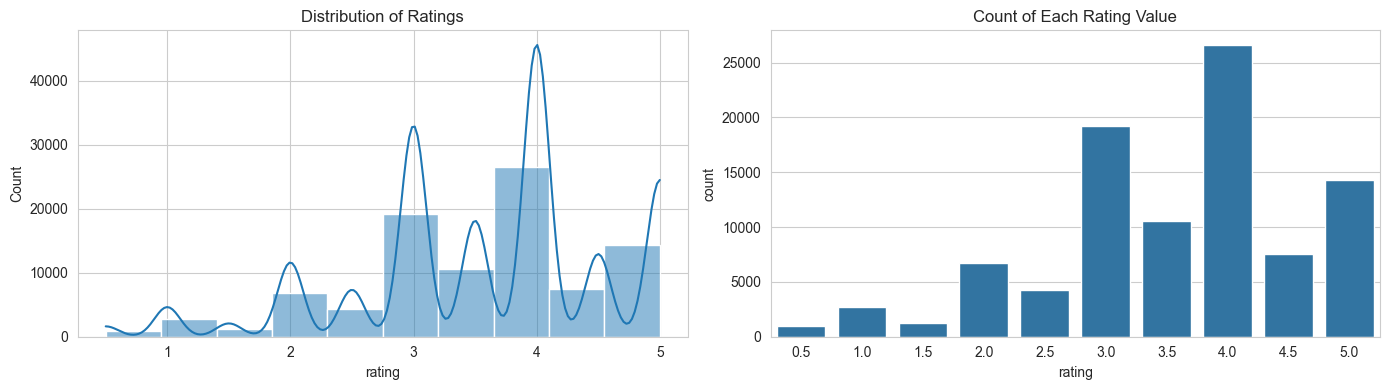

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(ratings['rating'], bins=10, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Ratings')

sns.countplot(x='rating', data=ratings, ax=axes[1])
axes[1].set_title('Count of Each Rating Value')

plt.tight_layout()
plt.show()

Cell 4 — EDA: Ratings per User & per Movie


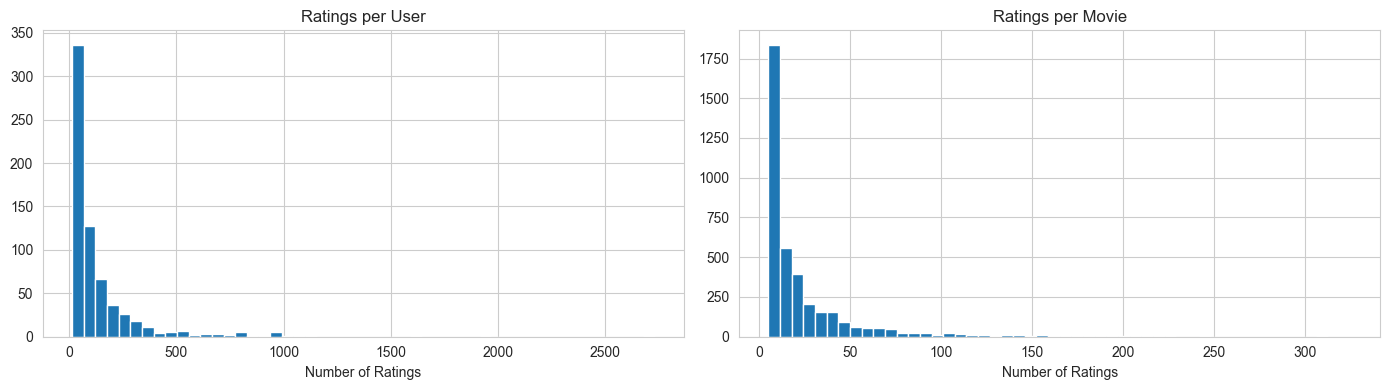

In [4]:
user_counts = ratings['userId'].value_counts()
movie_counts = ratings['movieId'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(user_counts, bins=50)
axes[0].set_title('Ratings per User')
axes[0].set_xlabel('Number of Ratings')

axes[1].hist(movie_counts, bins=50)
axes[1].set_title('Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')

plt.tight_layout()
plt.show()

Cell 5 — EDA: Ratings Over Time


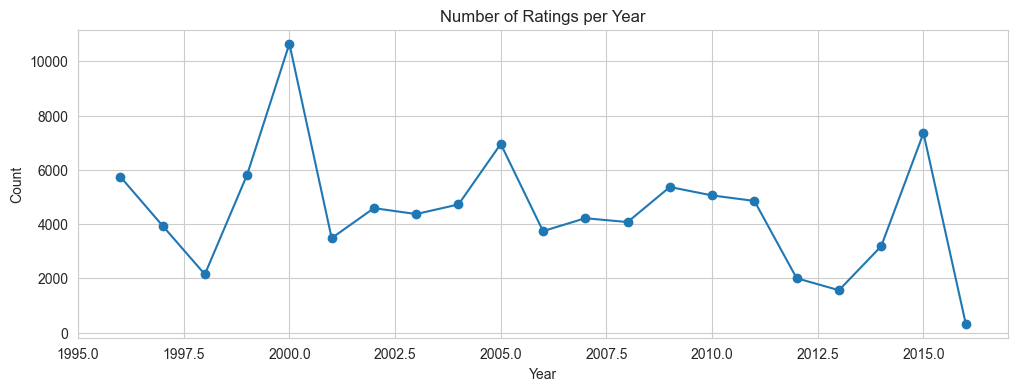

In [5]:
ratings_by_year = ratings.groupby('year').size()

plt.figure(figsize=(12, 4))
ratings_by_year.plot(kind='line', marker='o')
plt.title('Number of Ratings per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

Cell 6 — Feature Engineering: Genres One-Hot Encoding


In [6]:
print("\n" + "=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

genres_dummies = movies['genres'].str.get_dummies(sep='|')
genres_dummies.columns = ['genre_' + c for c in genres_dummies.columns]
print(f"Genres one-hot encoded: {genres_dummies.shape[1]} genre columns")


FEATURE ENGINEERING
Genres one-hot encoded: 19 genre columns


Cell 7 — Feature Engineering: User & Movie Stats


In [7]:
user_stats = (
    ratings.groupby('userId')['rating']
    .agg(user_avg='mean', user_count='count')
    .reset_index()
)

movie_stats = (
    ratings.groupby('movieId')['rating']
    .agg(avg_rating='mean', num_ratings='count')
    .reset_index()
)

print(f"user_stats : {user_stats.shape}")
print(f"movie_stats: {movie_stats.shape}")

user_stats : (668, 3)
movie_stats: (3855, 3)


Cell 8 — Merge into Final Dataset


In [8]:
ratings_clean = ratings.merge(user_stats, on='userId', how='left')

movies_clean = pd.concat(
    [movies.reset_index(drop=True), genres_dummies.reset_index(drop=True)], axis=1
).merge(movie_stats, on='movieId', how='left')

final_df = ratings_clean.merge(movies_clean, on='movieId', how='left')

print(f"ratings_clean : {ratings_clean.shape}  | NaN: {ratings_clean.isnull().sum().sum()}")
print(f"movies_clean  : {movies_clean.shape}  | NaN: {movies_clean.isnull().sum().sum()}")
print(f"final_df      : {final_df.shape}  | NaN: {final_df.isnull().sum().sum()}")
display(final_df.head())

ratings_clean : (94121, 9)  | NaN: 0
movies_clean  : (3855, 25)  | NaN: 0
final_df      : (94121, 33)  | NaN: 0


,userId,movieId,rating,timestamp,year,month,is_reliable_movie,user_avg,user_count,title,genres,is_reliable,genre_Action,genre_Adventure,genre_Animation,genre_Children,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,genre_Fantasy,genre_Film-Noir,genre_Horror,genre_IMAX,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western,avg_rating,num_ratings
0,1,16,4.0,2008-08-05 00:56:33,2008,8,True,3.666667,111,Casino (1995),Crime|Drama,True,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,3.785714,84
1,1,24,1.5,2008-08-05 00:23:27,2008,8,True,3.666667,111,Powder (1995),Drama|Sci-Fi,True,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,2.894737,38
2,1,32,4.0,2008-08-05 00:30:46,2008,8,True,3.666667,111,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller,True,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,3.939614,207
3,1,47,4.0,2008-08-05 00:35:56,2008,8,True,3.666667,111,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,True,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,4.130102,196
4,1,50,4.0,2008-08-05 00:35:23,2008,8,True,3.666667,111,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,True,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,4.328947,228


Cell 9 — Feature Selection & Save


In [9]:
# Drop columns not useful for modeling
final_df = final_df.drop(columns=['is_reliable_movie', 'is_reliable'], errors='ignore')

# Save the final dataset for Week 5 (Modeling)
final_df.to_csv(PROCESSED_DIR / 'final_df.csv', index=False)
movies_clean.to_csv(PROCESSED_DIR / 'movies_clean_features.csv', index=False)
print(f"final_df saved: {final_df.shape}")
print("Ready for Week 5 - Machine Learning")

final_df saved: (94121, 31)
Ready for Week 5 - Machine Learning
